In [ ]:
import os

import ast
import pandas as pd
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed
from ot import sliced_wasserstein_distance
import random
import itertools
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from cluster_weather_years.helper_functions import standardize_df
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    HYDROLOGICAL_YEARS,
    # NUM_CLUSTERS,
    COUNTRIES,
)
from sa_settings import MATCH_COUNTRIES, NUM_CLUSTERS

In [2]:
# config

NUM_DRAWS = 1e2  # number of random draws to compare with

# RUN_ID = "NL_20251003_1321" # NL 30 years
RUN_ID = "20250930_1356"  # Multi-country
RUN_ID_alternative = "BE_20251001_1623"  # BE

seed = 42
random.seed(seed)


# 1. Build dataframes

In [3]:
# build df
DF_PROD_DEMAND_FNAME = os.path.join(
    BASE_OUTPUT, "dataframes/df_prod_demand_daily_multi_country_WRONG_CAPACITIES.csv"
)
SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")

ALL_MATCH_COUNTRIES = ["NL", "BE", "FR", "DE"]
vars_to_match = (
    [f"{country}_OFF_prod" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_ON_prod" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_SOLAR_prod" for country in ALL_MATCH_COUNTRIES]
    + [f"{country}_Demand" for country in ALL_MATCH_COUNTRIES]
)

vars_to_standardize = vars_to_match  # df_daily.columns[3:-1].values
df_std = standardize_df(df_daily, vars_to_standardize)

In [5]:
df_selections = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID}/results_grid.csv"), index_col=0
)
df_sel_multi_country = df_selections.query(
    "optimized_metric == 'wasserstein_score'"
).sort_values("best_score", ascending=True)

df_selections_alternative = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_alternative}/results_grid.csv"),
    index_col=0,
)
df_sel_alternative = df_selections_alternative.query(
    "optimized_metric == 'wasserstein_score'"
).sort_values("best_score", ascending=True)

# df_sel_multi_country = df_sel_multi_country.sample(
#     len(df_sel_alternative), random_state=seed
# )

centroids_k_medoids = pd.read_csv(
    os.path.join(BASE_OUTPUT, "centroids/centroid_years_cf.csv"), index_col=0
)
centroids_k_medoids_sel = centroids_k_medoids[["model", "Hydrological_year"]].values

In [6]:
def build_df_centroids(df_daily, selected, mode="Hydrological_year"):
    """
    Build df with daily data of selected years
    """
    frames_centroids = []
    for i, (model, year) in enumerate(selected):
        # model_centroid, year_centroid = row["model"], row["Date"]
        if mode == "Hydrological_year":
            df_centroid = df_daily.query(
                f"model == '{model}' and Hydrological_year == {year}"
            )
        elif mode == "Calendar_year":
            df_centroid = df_daily.query(
                f"model == '{model}' and Calendar_year == {year}"
            )
        frames_centroids.append(df_centroid)

    return pd.concat(frames_centroids, ignore_index=True)


def build_df_random(df_daily, num_random=NUM_CLUSTERS):
    # build random selection df, based on random draw of NUM_CLUSTER years for comparison
    model_years = list(itertools.product(MODELS, HYDROLOGICAL_YEARS))
    random_models_years = random.sample(model_years, k=num_random)

    frames_random = []
    for model_random, year_random in random_models_years:
        df_random = df_daily.query(
            f"model == '{model_random}' and Hydrological_year == {year_random}"
        )
        frames_random.append(df_random)
    return pd.concat(frames_random, ignore_index=True)

In [7]:
def _qq_probabilities_and_weights():
    dense = np.linspace(0.005, 0.05, 100, endpoint=False)
    coarse = np.linspace(0.05, 0.995, 96)
    probs = np.concatenate([dense, coarse])
    w = np.empty_like(probs)
    w[1:-1] = (probs[2:] - probs[:-2]) / 2
    w[0] = (probs[1] - probs[0]) / 2
    w[-1] = (probs[-1] - probs[-2]) / 2
    return probs, w


def qq_compute_metrics(df_daily, datasets, columns):
    """
    Compute QQ-based metrics for one or many datasets vs the full df_daily.

    Parameters
    - df_daily: reference dataframe (full climatology)
    - datasets: dict[str, pd.DataFrame], e.g. {"Centroid": df_centroids, "Random": df_random}
    - columns: list[str] variables to analyze

    Returns
    - pd.DataFrame with rows per (dataset, variable) and columns [MAE, RMSE, MaxAbs]
    """
    probs, w = _qq_probabilities_and_weights()
    rows = []
    wass_scores = []
    df_daily_np = df_daily[columns].to_numpy()

    for name, df in datasets.items():
        wass_df = sliced_wasserstein_distance(
            df[columns].to_numpy(), df_daily_np, n_projections=50
        )
        wass_scores.append({"dataset": name, "Wasserstein": wass_df})

    for col in columns:
        q_full = df_daily[col].quantile(probs)
        median_full = df_daily[col].quantile(0.5)
        x = q_full.values
        for name, df in datasets.items():
            q_sub = df[col].quantile(probs)
            diff = (q_sub - q_full).values

            rows.append(
                {
                    "dataset": name,
                    "variable": col,
                    "MAE": float(np.average(np.abs(diff), weights=w)),
                    "RMSE": float(np.sqrt(np.average(diff**2, weights=w))),
                    "MaxAbs": float(np.max(np.abs(diff))),
                    "Median of VAR": float(median_full),
                    "x_min": float(np.nanmin(x)),
                    "x_max": float(np.nanmax(x)),
                }
            )

    return pd.DataFrame(rows), pd.DataFrame(wass_scores)

In [8]:
def qq_compute_metrics_parallel(
    df_daily, datasets, columns, n_projections=50, max_workers=None, show_progress=True
):
    """
    Parallel QQ-based metrics for datasets vs reference.

    Parameters
    ----------
    df_daily : pd.DataFrame
        Reference dataframe (full climatology).
    datasets : dict[str, pd.DataFrame]
        Mapping like {"Centroid": df_centroids, "Random": df_random}.
    columns : list[str]
        Variables to analyze.
    n_projections : int, optional
        Number of projections for sliced Wasserstein distance.
    max_workers : int | None, optional
        Max parallel workers for threads.

    Returns
    -------
    pd.DataFrame
        Rows per (dataset, variable) with [MAE, RMSE, MaxAbs, Median of VAR, x_min, x_max].
    pd.DataFrame
        Wasserstein scores per dataset.
    """
    probs, w = _qq_probabilities_and_weights()
    df_daily_np = df_daily[columns].to_numpy()

    q_full_map = {}
    for col in columns:
        q_full = df_daily[col].quantile(probs)
        q_full_map[col] = {
            "q": q_full.values,
            "median": float(df_daily[col].quantile(0.5)),
            "mean": float(df_daily[col].mean()),
            "x_min": float(np.nanmin(q_full.values)),
            "x_max": float(np.nanmax(q_full.values)),
        }

    def _worker(name_df):
        name, df = name_df
        rows = []
        wass = float(
            sliced_wasserstein_distance(
                df[columns].to_numpy(), df_daily_np, n_projections=n_projections
            )
        )
        for col in columns:
            q_sub = df[col].quantile(probs).values
            mean_sub = float(df[col].mean())
            diff = q_sub - q_full_map[col]["q"]
            diff_mean = mean_sub - q_full_map[col]["mean"]
            rows.append(
                {
                    "dataset": name,
                    "variable": col,
                    # "MAE": float(np.average(np.abs(diff), weights=w)),
                    "RMSE": float(np.sqrt(np.average(diff**2, weights=w))),
                    "Mean diff (sub-full)": float(diff_mean),
                    # "MaxAbs": float(np.max(np.abs(diff))),
                    "Median of VAR": q_full_map[col]["median"],
                    "x_min": q_full_map[col]["x_min"],
                    "x_max": q_full_map[col]["x_max"],
                }
            )
        return rows, {"dataset": name, "Wasserstein": wass}

    all_rows, wass_scores = [], []
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        futures = [ex.submit(_worker, item) for item in datasets.items()]
        pbar = tqdm(
            total=len(futures),
            disable=not show_progress,
            desc="QQ metrics",
            unit="dataset",
            leave=False,
        )
        try:
            for fut in as_completed(futures):
                rows, wass = fut.result()
                all_rows.extend(rows)
                wass_scores.append(wass)
                pbar.update(1)
        finally:
            pbar.close()

    return pd.DataFrame(all_rows), pd.DataFrame(wass_scores)


# 2. Compute metrics

In [9]:
columns = vars_to_standardize.copy()

# Create datasets dictionary with all available selections from df_sel_combined
datasets = {}

for i in range(len(df_sel_multi_country)):
    datasets[f"Multi-country {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_multi_country.iloc[i]["selected"])
    )

# for i in range(int(NUM_DRAWS)):
#     datasets[f"Random_N {i + 1}"] = build_df_random(df_daily, num_random=NUM_CLUSTERS)

# for i in range(len(df_sel_alternative)):
#     datasets[f"Alternative {i + 1}"] = build_df_centroids(
#         df_daily, eval(df_sel_alternative.iloc[i]["selected"])
#     )

# datasets["K_medoids"] = build_df_centroids(
#     df_daily, centroids_k_medoids_sel, mode="Calendar_year"
# )

In [ ]:
# df_metrics, df_wass = qq_compute_metrics_parallel(df_daily, datasets, columns)
# HACK: compute all 45 Multi-country SA experiments (instead of just 15)
# df_metrics_extra, df_wass_extra = qq_compute_metrics_parallel(
#     df_daily, datasets, columns
# )

# df_metrics.to_csv("df_metrics.csv")
# df_wass.to_csv("df_wass.csv")

# df_metrics = pd.concat([df_metrics, df_metrics_extra], ignore_index=True)
# df_wass = pd.concat([df_wass, df_wass_extra], ignore_index=True)
df_metrics, df_wass = (
    pd.read_csv(
        "../outputs/metrics_random_draws/df_metrics_N=100000.0.csv", index_col=0
    ),
    pd.read_csv("../outputs/metrics_random_draws/df_wass_N=100000.0.csv", index_col=0),
)

# df_metrics = df_metrics[~df_metrics["dataset"].str.contains("Multi")]
# df_metrics = pd.concat([df_metrics, df_metrics_extra], ignore_index=True)
# df_wass = df_wass[~df_wass["dataset"].str.contains("Multi")]
# df_wass = pd.concat([df_wass, df_wass_extra], ignore_index=True)

In [10]:
# can be deleted I think?

# df_worst = pd.DataFrame()
# df_median_rmse = pd.DataFrame()
# df_mean = pd.DataFrame()
# for dataset in df_metrics["dataset"].unique():
#     dataset_metrics = df_metrics[df_metrics["dataset"] == dataset]
#     df_worst = pd.concat(
#         [
#             df_worst,
#             dataset_metrics[dataset_metrics["RMSE"] == dataset_metrics["RMSE"].max()],
#         ]
#     )
#     df_median_rmse = pd.concat(
#         [
#             df_median_rmse,
#             dataset_metrics.loc[
#                 (dataset_metrics["RMSE"] - dataset_metrics["RMSE"].median())
#                 .abs()
#                 .idxmin()
#             ]
#             .to_frame()
#             .T,
#         ]
#     )

#     df_mean = pd.concat(
#         [
#             df_mean,
#             dataset_metrics[
#                 dataset_metrics["Mean diff (sub-full)"]
#                 == dataset_metrics["Mean diff (sub-full)"].max()
#             ],
#         ]
#     )

# wass_random = df_wass[df_wass["dataset"].str.contains("Random")]
# wass_multi = df_wass[df_wass["dataset"].str.contains("Multi-country")]

# mean_random = df_mean[df_mean["dataset"].str.contains("Random")]
# mean_multi = df_mean[df_mean["dataset"].str.contains("Multi-country")]

# median_rmse_random = df_median_rmse[df_median_rmse["dataset"].str.contains("Random")]
# median_rmse_multi = df_median_rmse[
#     df_median_rmse["dataset"].str.contains("Multi-country")
# ]

KeyboardInterrupt: 

In [14]:
g.columns

Index(['dataset', 'variable', 'RMSE', 'Relative mean diff ((sub-full)/full)',
       'Median of VAR', 'x_min', 'x_max'],
      dtype='object')

In [12]:
# agg = df_metrics.groupby("dataset", as_index=False).agg(
#     worst_rmse=("RMSE", "max"),
#     median_rmse=("RMSE", "median"),
#     max_mean_diff=("Mean diff (sub-full)", "max"),
# )
# # HACK: is now fixed already in many_random_vs_sa.py, so can be deleted after re-calc there.
# agg["max_mean_diff"] = np.abs(agg["max_mean_diff"])

# merged = agg.merge(df_wass[["dataset", "Wasserstein"]], on="dataset", how="left")

# out = pd.DataFrame(
#     {
#         "dataset": merged["dataset"],
#         "rank_worst_rmse": merged["worst_rmse"]
#         .rank(method="min", ascending=True)
#         .astype(int),
#         "rank_median_rmse": merged["median_rmse"]
#         .rank(method="min", ascending=True)
#         .astype(int),
#         "rank_mean_diff": merged["max_mean_diff"]
#         .rank(method="min", ascending=True)
#         .astype(int),
#         "rank_wass": merged["Wasserstein"]
#         .rank(method="min", ascending=True)
#         .astype("Int64"),
#     }
# )

# Aggregate metrics and keep associated variables
agg_list = []
for ds, g in df_metrics.groupby("dataset"):
    # Worst RMSE
    worst_idx = g["RMSE"].idxmax()
    worst_rmse = g.loc[worst_idx, "RMSE"]
    worst_var = g.loc[worst_idx, "variable"]

    # Median RMSE (closest to median)
    med_val = g["RMSE"].median()
    med_idx = (g["RMSE"] - med_val).abs().idxmin()
    median_rmse = g.loc[med_idx, "RMSE"]
    median_rmse_var = g.loc[med_idx, "variable"]

    # Max mean diff
    diff_idx = np.abs(g["Relative mean diff ((sub-full)/full)"]).idxmax()
    max_mean_diff = np.abs(g.loc[diff_idx, "Relative mean diff ((sub-full)/full)"])
    diff_mean_var = g.loc[diff_idx, "variable"]

    agg_list.append(
        {
            "dataset": ds,
            "worst_rmse": worst_rmse,
            "worst_rmse_var": worst_var,
            "median_rmse": median_rmse,
            "median_rmse_var": median_rmse_var,
            "max_mean_diff": max_mean_diff,
            "max_mean_diff_var": diff_mean_var,
        }
    )

agg = pd.DataFrame(agg_list)

agg = agg.merge(df_wass[["dataset", "Wasserstein"]], on="dataset", how="left")

# Compute ranks
out = pd.DataFrame(
    {
        "dataset": agg["dataset"],
        "rank_worst_rmse": agg["worst_rmse"].rank(method="min").astype(int),
        "worst_rmse_var": agg["worst_rmse_var"],
        "rank_median_rmse": agg["median_rmse"].rank(method="min").astype(int),
        "median_rmse_var": agg["median_rmse_var"],
        "rank_mean_diff": agg["max_mean_diff"].rank(method="min").astype(int),
        "max_mean_diff_var": agg["max_mean_diff_var"],
        "rank_wass": agg["Wasserstein"].rank(method="min").astype("Int64"),
    }
)


mean_rank = out[["rank_worst_rmse", "rank_mean_diff", "rank_wass"]].mean(axis=1)
worst_rank = out[["rank_worst_rmse", "rank_mean_diff", "rank_wass"]].max(axis=1)

mean_rank = out[["rank_worst_rmse", "rank_wass"]].mean(axis=1)
worst_rank = out[["rank_worst_rmse", "rank_wass"]].max(axis=1)

out["mean_rank"] = mean_rank
out["worst_rank"] = worst_rank

# 3. Find 'best' selection across multiple metrics

In [13]:
df_wass.sort_values("Wasserstein")[:15]

,dataset,Wasserstein
7,Multi-country 8,2.267870
5,Multi-country 4,2.334300
11,Multi-country 5,2.334897
0,Multi-country 1,2.337377
20,Multi-country 11,2.339646
62328,Random_N 62280,2.379402
10,Multi-country 9,2.400748
12,Multi-country 14,2.404666
70381,Random_N 70335,2.417441
91144,Random_N 91091,2.418980


In [14]:
agg.query("dataset.str.contains('Multi')")[
    ["dataset", "max_mean_diff", "max_mean_diff_var"]
].sort_values("max_mean_diff", ascending=True)

,dataset,max_mean_diff,max_mean_diff_var
56,Multi-country 5,0.009393,NL_ON_prod
50,Multi-country 40,0.011636,BE_SOLAR_prod
17,Multi-country 10,0.011870,BE_ON_prod
21,Multi-country 14,0.011888,BE_ON_prod
47,Multi-country 38,0.012433,BE_ON_prod
24,Multi-country 17,0.013149,DE_OFF_prod
27,Multi-country 2,0.013423,FR_ON_prod
58,Multi-country 7,0.013691,DE_ON_prod
44,Multi-country 35,0.013784,NL_ON_prod
60,Multi-country 9,0.013784,FR_ON_prod


In [15]:
agg[["dataset", "max_mean_diff", "max_mean_diff_var"]].sort_values(
    "max_mean_diff", ascending=True
)

,dataset,max_mean_diff,max_mean_diff_var
63,Random_N 100,0.004674,FR_OFF_prod
95069,Random_N 95505,0.007576,NL_ON_prod
69842,Random_N 72800,0.007904,FR_ON_prod
44191,Random_N 49715,0.007948,NL_OFF_prod
71271,Random_N 74087,0.008177,FR_ON_prod
...,...,...,...
27448,Random_N 34646,0.161106,DE_ON_prod
51645,Random_N 56423,0.161231,NL_ON_prod
99485,Random_N 99480,0.161595,NL_ON_prod
54678,Random_N 59153,0.162265,BE_ON_prod


In [16]:
agg[["dataset", "worst_rmse", "worst_rmse_var"]].sort_values(
    "worst_rmse", ascending=True
)

,dataset,worst_rmse,worst_rmse_var
71271,Random_N 74087,2.582107,FR_OFF_prod
46470,Random_N 51766,2.740058,BE_OFF_prod
33,Multi-country 25,2.836923,DE_OFF_prod
60,Multi-country 9,2.840702,NL_OFF_prod
66094,Random_N 69428,2.842009,DE_OFF_prod
...,...,...,...
24575,Random_N 3206,30.058792,BE_OFF_prod
53056,Random_N 57694,30.696455,BE_OFF_prod
75918,Random_N 7827,30.738409,BE_OFF_prod
81939,Random_N 83689,30.998703,BE_OFF_prod


In [17]:
out[["dataset", "mean_rank"]].sort_values("mean_rank")

,dataset,mean_rank
49,Multi-country 4,4.5
60,Multi-country 9,5.5
16,Multi-country 1,6.5
46470,Random_N 51766,7.5
33,Multi-country 25,11.5
...,...,...
68535,Random_N 71624,100054.5
55350,Random_N 59759,100055.0
75918,Random_N 7827,100056.0
56051,Random_N 60389,100056.5


In [18]:
out.sort_values("worst_rank")

,dataset,rank_worst_rmse,worst_rmse_var,rank_median_rmse,median_rmse_var,rank_mean_diff,max_mean_diff_var,rank_wass,mean_rank,worst_rank
60,Multi-country 9,4,NL_OFF_prod,6935,FR_OFF_prod,316,FR_ON_prod,7,5.5,7
49,Multi-country 4,7,DE_SOLAR_prod,439,NL_OFF_prod,1838,DE_ON_prod,2,4.5,7
16,Multi-country 1,9,FR_OFF_prod,820,BE_Demand,2650,BE_ON_prod,4,6.5,9
17,Multi-country 10,13,DE_OFF_prod,139,FR_OFF_prod,93,BE_ON_prod,11,12.0,13
46470,Random_N 51766,2,BE_OFF_prod,4974,FR_OFF_prod,50,DE_ON_prod,13,7.5,13
...,...,...,...,...,...,...,...,...,...,...
75918,Random_N 7827,100059,BE_OFF_prod,98983,DE_ON_prod,100042,BE_ON_prod,100053,100056.0,100059
81939,Random_N 83689,100060,BE_OFF_prod,99705,FR_ON_prod,100033,BE_ON_prod,99947,100003.5,100060
55350,Random_N 59759,100050,BE_OFF_prod,100053,DE_Demand,100044,NL_ON_prod,100060,100055.0,100060
99485,Random_N 99480,100061,BE_OFF_prod,99958,DE_ON_prod,100059,NL_ON_prod,100030,100045.5,100061


In [19]:
agg_random = agg[agg["dataset"].str.contains("Random")]
agg_sa = agg[agg["dataset"].str.contains("Multi-country")]

(array([1.12716617, 1.61023739, 1.61023739, 1.77126113, 1.12716617]),
 array([2.26786989, 2.40587577, 2.54388165, 2.68188752, 2.8198934 ,
        2.95789928]),
 <BarContainer object of 5 artists>)

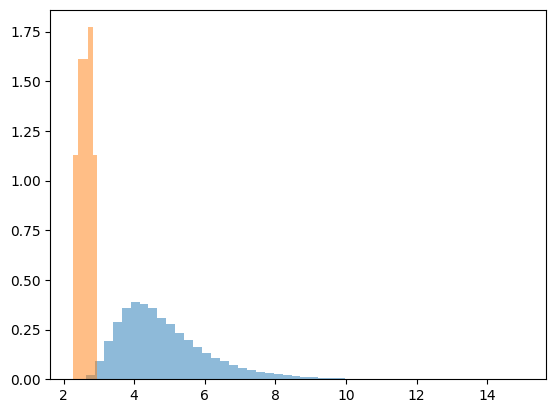

In [20]:
plt.hist(agg_random["Wasserstein"], bins=50, alpha=0.5, density=True)
plt.hist(agg_sa["Wasserstein"], bins=5, alpha=0.5, density=True)

(array([0.42096644, 0.50515973, 0.50515973, 0.25257986, 0.42096644,
        0.50515973, 0.42096644, 0.42096644, 0.08419329, 0.25257986]),
 array([2.83692317, 3.10086609, 3.36480901, 3.62875193, 3.89269485,
        4.15663778, 4.4205807 , 4.68452362, 4.94846654, 5.21240946,
        5.47635238]),
 <BarContainer object of 10 artists>)

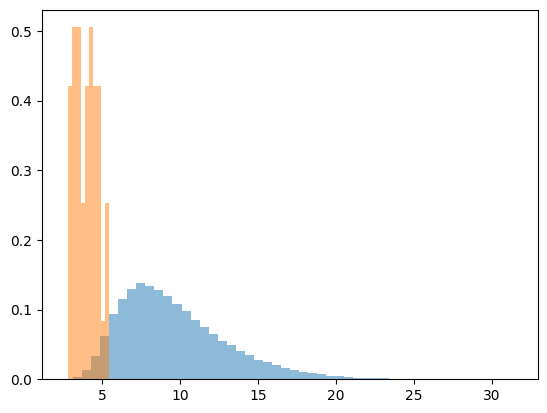

In [21]:
plt.hist(agg_random["worst_rmse"], bins=50, alpha=0.5, density=True)
plt.hist(agg_sa["worst_rmse"], bins=10, alpha=0.5, density=True)

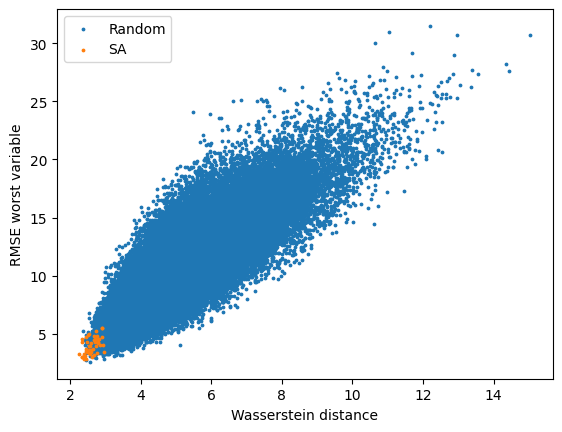

In [22]:
plt.scatter(agg_random["Wasserstein"], agg_random["worst_rmse"], s=3)
plt.scatter(agg_sa["Wasserstein"], agg_sa["worst_rmse"], s=3)
plt.xlabel("Wasserstein distance")
plt.ylabel("RMSE worst variable")
plt.legend(["Random", "SA"])

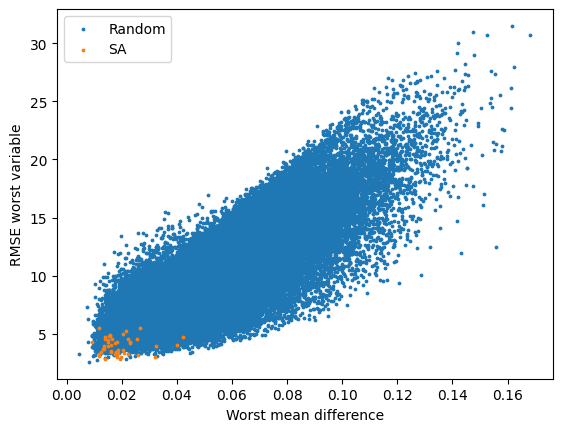

In [23]:
plt.scatter(agg_random["max_mean_diff"], agg_random["worst_rmse"], s=3)
plt.scatter(agg_sa["max_mean_diff"], agg_sa["worst_rmse"], s=3)
plt.xlabel("Worst mean difference")
plt.ylabel("RMSE worst variable")
plt.legend(["Random", "SA"])

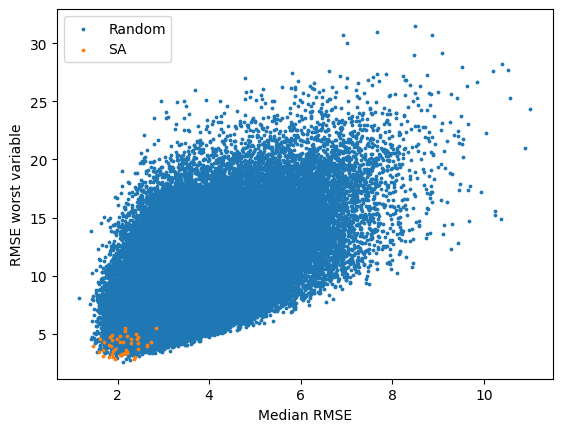

In [24]:
plt.scatter(agg_random["median_rmse"], agg_random["worst_rmse"], s=3)
plt.scatter(agg_sa["median_rmse"], agg_sa["worst_rmse"], s=3)
plt.xlabel("Median RMSE")
plt.ylabel("RMSE worst variable")
plt.legend(["Random", "SA"])

In [25]:
out[["dataset", "mean_rank", "worst_rank"]].sort_values("mean_rank")

,dataset,mean_rank,worst_rank
49,Multi-country 4,4.5,7
60,Multi-country 9,5.5,7
16,Multi-country 1,6.5,9
46470,Random_N 51766,7.5,13
33,Multi-country 25,11.5,20
...,...,...,...
68535,Random_N 71624,100054.5,100057
55350,Random_N 59759,100055.0,100060
75918,Random_N 7827,100056.0,100059
56051,Random_N 60389,100056.5,100059


# 4. Analyse 'best' selection

In [ ]:
NUM_CLUSTERS = 5  # HARCODE
df_best = datasets["Multi-country 9"]
# df_random = build_df_random(df_daily, num_random=NUM_CLUSTERS)
# df_random = datasets["Random_N 74087"]

In [52]:
good_random_model_years = pd.read_csv(
    "../outputs/metrics_random_draws/good_random_model_years_N=5.csv"
)
# good_random_model_years['dataset'] = 'Random_N 51766'
random_model_years = (
    good_random_model_years.query('dataset == "Random_N 51766"').iloc[0, 1:].tolist()
)

tuples = [ast.literal_eval(item) for item in random_model_years]
df_random_best = build_df_centroids(df_daily, tuples)


In [55]:
def ecdf_comparison(df_daily, df_centroids, df_random, columns):
    fig, axs = plt.subplots(2, 2, figsize=(12, 10), sharey=True)

    for i, col in enumerate(columns):
        ax = axs.flat[i]
        sns.ecdfplot(df_centroids, x=col, label="Centroid years", ax=ax)
        sns.ecdfplot(df_random, x=col, label="Randomly sampled years", ax=ax)
        sns.ecdfplot(df_daily, x=col, label="Full climatology", ax=ax)
        ax.set_title(col)
        ax.set_ylim(0, 1.02)
        ax.legend(loc="lower right")

    # Hide any unused axes (in case columns < 4)
    for j in range(len(columns), 4):
        axs.flat[j].axis("off")

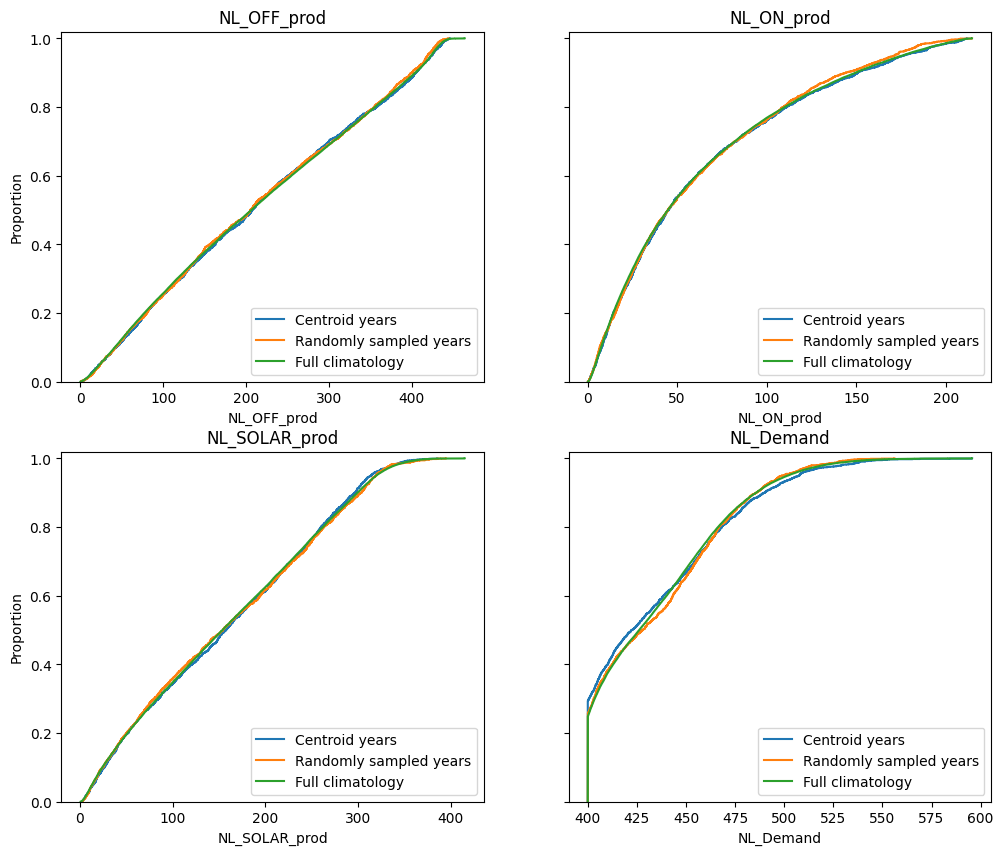

In [56]:
country = "NL"
columns_plot = [
    f"{country}_OFF_prod",
    f"{country}_ON_prod",
    f"{country}_SOLAR_prod",
    f"{country}_Demand",
]
ecdf_comparison(df_daily, df_best, df_random_best, columns_plot)

In [57]:
def _qq_probabilities_and_weights():
    dense = np.linspace(0.005, 0.05, 100, endpoint=False)
    coarse = np.linspace(0.05, 0.995, 96)
    probs = np.concatenate([dense, coarse])
    w = np.empty_like(probs)
    w[1:-1] = (probs[2:] - probs[:-2]) / 2
    w[0] = (probs[1] - probs[0]) / 2
    w[-1] = (probs[-1] - probs[-2]) / 2
    return probs, w


def qq_plot(df_daily, datasets, columns):
    """
    Plot QQ curves and quantile differences for provided datasets vs full df.

    Parameters
    - df_daily: reference dataframe (full climatology)
    - datasets: dict[str, pd.DataFrame], e.g. {"Centroid": df_centroids, "Random": df_random}
    - columns: list[str]
    """
    probs, _ = _qq_probabilities_and_weights()
    fig_qq, axs_qq = plt.subplots(2, 2, figsize=(12, 10))
    fig_diff, axs_diff = plt.subplots(2, 2, figsize=(12, 10), sharey=False)

    for i, col in enumerate(columns):
        q_full = df_daily[col].quantile(probs)
        x = q_full.values

        # QQ plot
        axq = axs_qq.flat[i]
        for j, (name, df) in enumerate(datasets.items()):
            q_sub = df[col].quantile(probs)
            axq.plot(x, q_sub.values, label=name)
        lo, hi = np.nanmin(x), np.nanmax(x)
        axq.plot([lo, hi], [lo, hi], "k--", lw=1, label="y=x")
        axq.set_title(f"QQ: {col}")
        axq.set_xlabel("Full climatology value")
        axq.set_ylabel("Subset value")
        axq.legend(loc="best")

        # Differences
        axd = axs_diff.flat[i]
        for j, (name, df) in enumerate(datasets.items()):
            q_sub = df[col].quantile(probs)
            diff = (q_sub - q_full).values
            axd.plot(probs, diff, color=f"C{j}", label=f"{name} - Full")
            axd.plot(probs, np.abs(diff), color=f"C{j}", ls="--")
        axd.axhline(0.0, color="k", lw=1, ls="--")
        axd.set_title(f"QQ-differences: {col}")
        axd.set_xlabel("Quantile")
        axd.set_ylabel("Δ value")
        axd.legend(loc="best")

    for j in range(len(columns), 4):
        axs_qq.flat[j].axis("off")
        axs_diff.flat[j].axis("off")

    fig_qq.tight_layout()
    fig_diff.tight_layout()

    return fig_qq, fig_diff

(<Figure size 1200x1000 with 4 Axes>, <Figure size 1200x1000 with 4 Axes>)

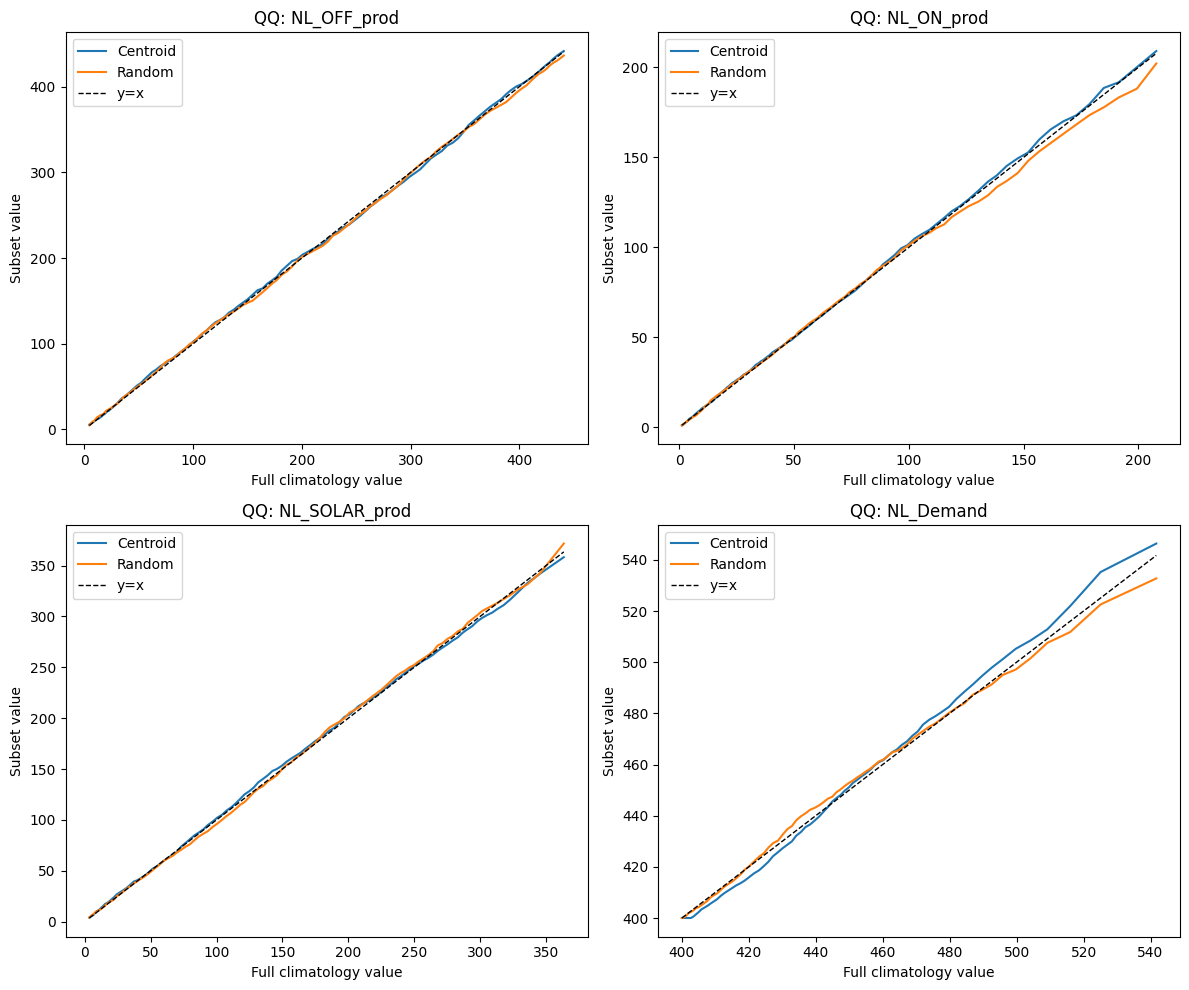

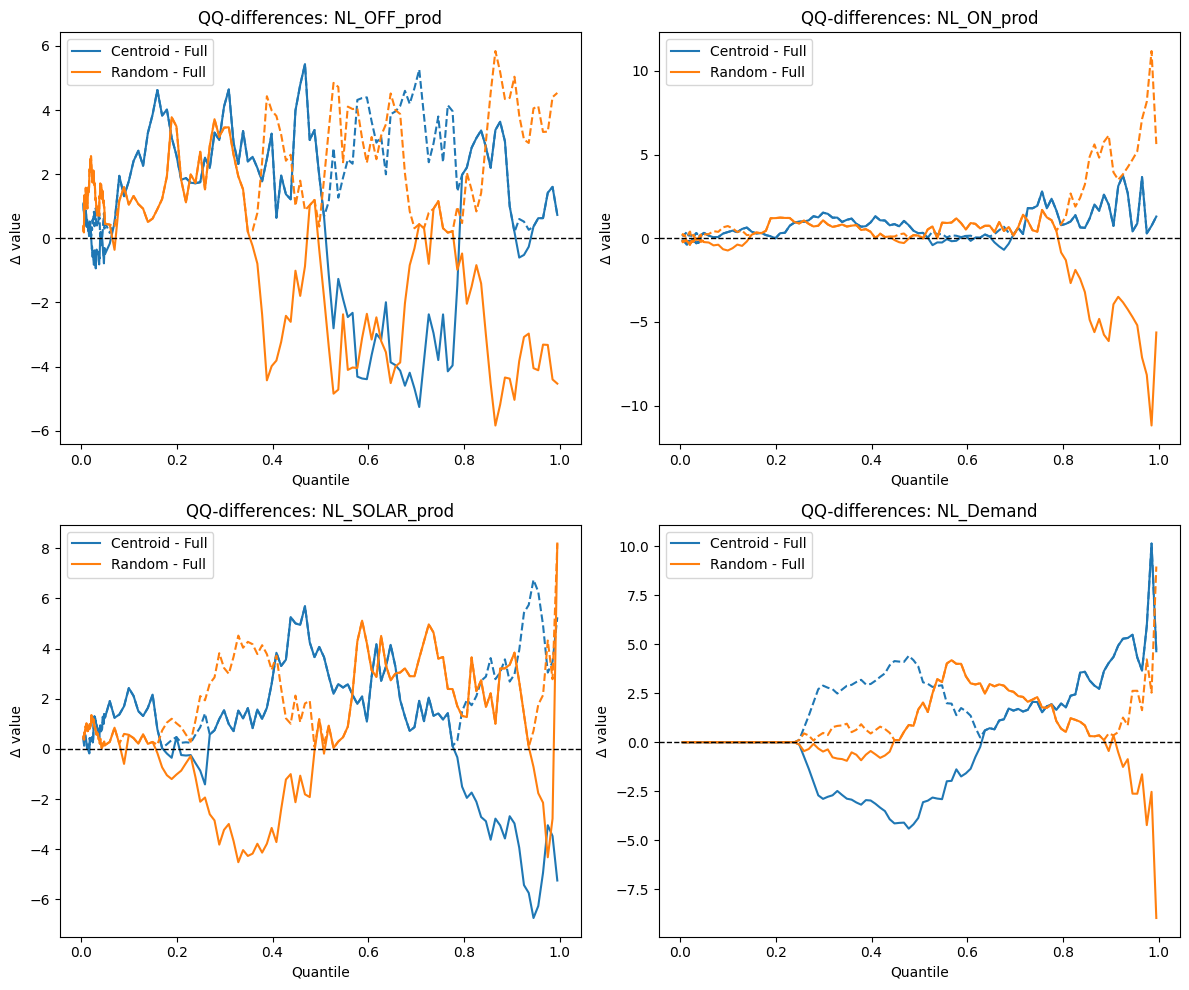

In [58]:
qq_plot(df_daily, {"Centroid": df_best, "Random": df_random_best}, columns_plot)